# MenuScan TN · 02.01 Règles d'association et plats recommandés (T7.3, EF-12)

Autrice : Sarra Abdeljaouad

**Question.** Quels plats ou catégories sont commandés ensemble plus souvent que le hasard ne le voudrait ? Que proposer, sur la carte de chaque établissement Pro, à côté de chaque plat ?

**Données.** Commandes servies avec lignes de détail, de 2024 à 2026 (schéma `marts`).

**Méthode.**
1. Règles apprises sur 2024-2025, vérifiées sur 2026.
2. Lift **ajusté par établissement** : on compare chaque panier à ce qu'on attendrait dans le même établissement.
3. Une paire n'est retenue que si elle passe un test statistique corrigé pour le nombre de paires testées.

In [10]:
import sys
sys.path.insert(0, "../00_commun")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import association_rules, fpgrowth

from menuscan_analytics import chargement, config, data_mining as dm, features
from menuscan_analytics.config import BLEU, GRIS, ORANGE

config.style()

## 1. Paniers

In [11]:
lignes = features.lignes_servies()
app, test = lignes[lignes.annee < 2026], lignes[lignes.annee == 2026]
paniers = lignes.groupby("commande_id").agg(annee=("annee", "first"), plats=("nom_article", "nunique"))
pd.DataFrame({
    "commandes": paniers.groupby("annee").size(),
    "avec 2 plats ou plus": paniers[paniers.plats >= 2].groupby("annee").size(),
    "plats différents (noms)": lignes.groupby("annee").nom_article.nunique(),
})

,commandes,avec 2 plats ou plus,plats différents (noms)
annee,,,
2024,8253,5801,87
2025,32125,22373,87
2026,63007,44149,87


Les 87 noms de plats sont communs à tous les établissements : un « Cappuccino » est le même plat partout. Chaque établissement n'en propose qu'une partie.

## 2. Pourquoi ne pas utiliser le lift brut

`mlxtend` calcule le support, la confiance et le lift sur l'ensemble des commandes. Ici, c'est trompeur. Deux catégories proposées dans les mêmes établissements (par exemple dans les cafés) semblent associées. Ce n'est pas que les clients les choisissent ensemble : c'est qu'elles sont à la carte des mêmes endroits.

Ci-dessous, le lift brut par catégorie, calculé avec `mlxtend` sur 2024-2025.

In [12]:
cat_app = pd.crosstab(app.commande_id, app.nom_categorie).gt(0)
frequents = fpgrowth(cat_app, min_support=0.005, use_colnames=True)
brut = association_rules(frequents, metric="lift", min_threshold=1.0)
brut = brut[(brut.antecedents.apply(len) == 1) & (brut.consequents.apply(len) == 1)].copy()
brut["antecedent"] = brut.antecedents.apply(lambda s: next(iter(s)))
brut["consequent"] = brut.consequents.apply(lambda s: next(iter(s)))
brut = brut[["antecedent", "consequent", "support", "confidence", "lift"]].rename(columns={"lift": "lift_brut"})

ajuste_cat = dm.regles(app, "nom_categorie")
comparaison = brut.merge(ajuste_cat[["antecedent", "consequent", "lift_ajuste"]], on=["antecedent", "consequent"])
comparaison.sort_values("lift_brut", ascending=False).head(12)

,antecedent,consequent,support,confidence,lift_brut,lift_ajuste
59,Pâtisseries,Thés et infusions,0.009,0.278,11.448,1.267
58,Thés et infusions,Pâtisseries,0.009,0.382,11.448,1.267
49,Accompagnements,Burgers,0.020,0.292,6.798,1.312
48,Burgers,Accompagnements,0.020,0.465,6.798,1.312
62,Glaces,Pâtisseries,0.005,0.225,6.762,0.799
63,Pâtisseries,Glaces,0.005,0.157,6.762,0.799
83,Entrées,Grillades,0.021,0.270,4.860,1.165
82,Grillades,Entrées,0.021,0.375,4.860,1.165
26,Pizzas,Accompagnements,0.013,0.310,4.528,0.834
27,Accompagnements,Pizzas,0.013,0.184,4.528,0.834


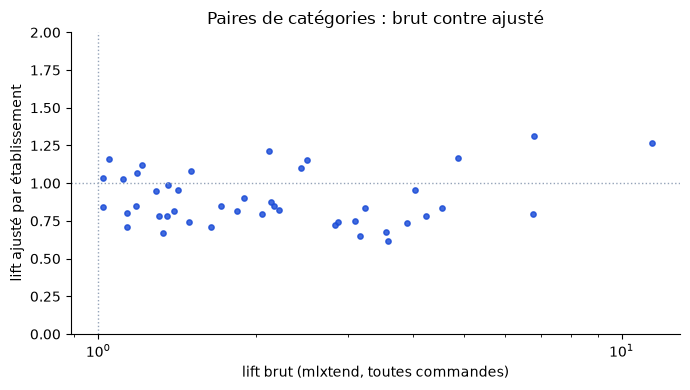

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(comparaison.lift_brut, comparaison.lift_ajuste, s=14, color=BLEU, alpha=0.6)
ax.axhline(1, color=GRIS, lw=1, ls=":"); ax.axvline(1, color=GRIS, lw=1, ls=":")
ax.set_xscale("log"); ax.set_ylim(0, 2)
ax.set_xlabel("lift brut (mlxtend, toutes commandes)"); ax.set_ylabel("lift ajusté par établissement")
ax.set_title("Paires de catégories : brut contre ajusté")
plt.tight_layout(); config.enregistrer_figure(fig, "DM01_lift_brut_ajuste"); plt.show()

**Lecture.** Le lift brut va jusqu'à 11, mais une fois l'effet établissement retiré, aucune paire ne dépasse 1,5. Presque tout le lift brut venait du fait que les catégories sont proposées dans les mêmes établissements. La suite n'utilise que le lift ajusté.

## 3. Associations entre catégories (apprentissage 2024-2025, vérification 2026)

Règles de sélection, fixées avant de regarder 2026 :
- lift ajusté d'au moins 1,2 ;
- p-value du test de Poisson inférieure à 0,05 divisé par le nombre de paires testées (correction de Bonferroni).

Le lift ajusté est **symétrique** : il dit que A et B vont ensemble, pas lequel entraîne l'autre. Le sens « A → B » d'une règle est une lecture, pas un résultat.

In [14]:
ret_cat = ajuste_cat[ajuste_cat.retenue].copy()
ret_cat = ret_cat[ret_cat.antecedent < ret_cat.consequent]            # une ligne par paire
ret_cat["lift_2026"] = dm.lift_sur(test, "nom_categorie", ret_cat)
print(f"{len(ajuste_cat) // 2} paires de catégories testées ; {len(ret_cat)} retenues ; "
      f"{(ret_cat.lift_2026 > 1).mean():.0%} gardent un lift > 1 en 2026")
config.enregistrer_table(ret_cat, "DM01_regles_categories", index=False)
ret_cat[["antecedent", "consequent", "commandes_ensemble", "lift_ajuste", "lift_2026"]]

76 paires de catégories testées ; 3 retenues ; 100% gardent un lift > 1 en 2026


,antecedent,consequent,commandes_ensemble,lift_ajuste,lift_2026
0,Accompagnements,Burgers,806.000,1.312,1.297
3,Pâtisseries,Thés et infusions,374.000,1.267,1.257
4,Jus frais,Petit-déjeuner,1 040.000,1.210,1.143


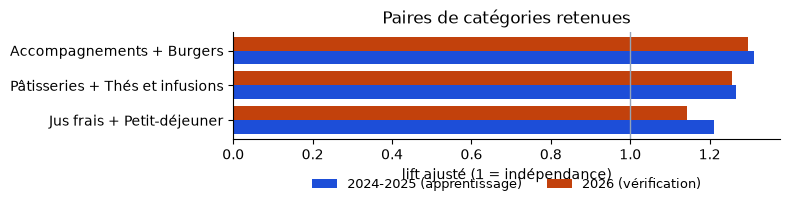

In [15]:
t = ret_cat.sort_values("lift_ajuste")
fig, ax = plt.subplots(figsize=(8, 0.45 * len(t) + 1))
y = np.arange(len(t))
ax.barh(y - 0.2, t.lift_ajuste, height=0.4, color=BLEU, label="2024-2025 (apprentissage)")
ax.barh(y + 0.2, t.lift_2026, height=0.4, color=ORANGE, label="2026 (vérification)")
ax.set_yticks(y, t.antecedent + " + " + t.consequent); ax.axvline(1, color=GRIS, lw=1)
ax.set_xlabel("lift ajusté (1 = indépendance)")
ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, frameon=False)
ax.set_title("Paires de catégories retenues")
plt.tight_layout(); config.enregistrer_figure(fig, "DM01_regles_categories"); plt.show()

## 4. Associations entre plats

In [16]:
ajuste_plat = dm.regles(app, "nom_article")
ret_plat = ajuste_plat[ajuste_plat.retenue].copy()
ret_plat = ret_plat[ret_plat.antecedent < ret_plat.consequent]
ret_plat["lift_2026"] = dm.lift_sur(test, "nom_article", ret_plat)
cat_de = lignes.drop_duplicates("nom_article").set_index("nom_article").nom_categorie
ret_plat["categories"] = ret_plat.antecedent.map(cat_de) + " + " + ret_plat.consequent.map(cat_de)
print(f"{len(ajuste_plat) // 2} paires de plats testées ; {len(ret_plat)} retenues ; "
      f"{(ret_plat.lift_2026 > 1).mean():.0%} gardent un lift > 1 en 2026")
config.enregistrer_table(ret_plat, "DM01_regles_plats", index=False)
ret_plat[["antecedent", "consequent", "categories", "commandes_ensemble", "confiance", "lift_ajuste", "lift_2026"]]

1911 paires de plats testées ; 10 retenues ; 100% gardent un lift > 1 en 2026


,antecedent,consequent,categories,commandes_ensemble,confiance,lift_ajuste,lift_2026
19,Cheeseburger,Frites,Burgers + Accompagnements,134.000,0.241,1.634,1.677
33,Burger poulet,Salade verte,Burgers + Accompagnements,138.000,0.225,1.592,1.368
34,Burger classique,Salade verte,Burgers + Accompagnements,104.000,0.175,1.582,1.442
39,Burger poulet,Frites fromage,Burgers + Accompagnements,137.000,0.216,1.579,1.321
40,Jus d'orange,Petit-déjeuner tunisien,Jus frais + Petit-déjeuner,110.000,0.095,1.576,1.399
44,Ojja merguez,Petit-déjeuner continental,Petit-déjeuner + Petit-déjeuner,101.000,0.097,1.554,1.610
59,Burger classique,Frites,Burgers + Accompagnements,144.000,0.242,1.534,1.384
60,Jus de fraise,Petit-déjeuner tunisien,Jus frais + Petit-déjeuner,121.000,0.082,1.521,1.252
84,Eau minérale 1 L,Thé glacé,Boissons fraîches + Boissons fraîches,173.000,0.117,1.451,1.131
159,Frites,Salade verte,Accompagnements + Accompagnements,237.000,0.210,1.329,1.307


**Lecture.** Au niveau des plats, le test est beaucoup plus exigeant : il y a des milliers de paires possibles et chaque paire est rare. Les paires retenues sont celles dont l'association est assez forte et assez fréquente pour ne pas être due au hasard.

## 5. Plats recommandés pour les établissements Pro

Pour chaque plat de la carte actuelle d'un établissement Pro, on propose jusqu'à 3 plats **de sa propre carte**. L'ordre de priorité est le suivant :
1. un plat lié par une **règle plat** retenue, par lift décroissant ;
2. puis un plat d'une **catégorie associée** par une règle catégorie retenue, du plus vendu au moins vendu dans l'établissement en 2026.

Un plat sans règle n'a pas de recommandation. On ne complète pas avec les plats les plus vendus : ce ne serait plus une association.

In [17]:
pro = chargement.lire("""
    select a.etablissement_id from marts.fait_abonnement_mensuel a join marts.dim_formule f using (formule_id)
    where a.mois = '2026-12-01' and f.nom_formule = 'Pro'""").etablissement_id
carte = chargement.lire("""
    select etablissement_id, nom_article, nom_categorie from marts.dim_article
    where est_prix_actuel and statut_article = 'propose'""")
carte = carte[carte.etablissement_id.isin(pro)].drop_duplicates()
vendus = test.groupby(["etablissement_id", "nom_article"]).quantite.sum()

lien_plat = pd.concat([ret_plat[["antecedent", "consequent", "lift_ajuste"]],
                       ret_plat.rename(columns={"antecedent": "consequent", "consequent": "antecedent"})
                       [["antecedent", "consequent", "lift_ajuste"]]])
lien_cat = pd.concat([ret_cat[["antecedent", "consequent"]],
                      ret_cat.rename(columns={"antecedent": "consequent", "consequent": "antecedent"})
                      [["antecedent", "consequent"]]])
cats_liees = lien_cat.groupby("antecedent").consequent.apply(set).to_dict()
plats_lies = lien_plat.sort_values("lift_ajuste", ascending=False).groupby("antecedent").consequent.apply(list).to_dict()

reco = []
for e, c in carte.groupby("etablissement_id"):
    disponibles = set(c.nom_article)
    cat_par_plat = dict(zip(c.nom_article, c.nom_categorie))
    for plat, cat in cat_par_plat.items():
        choix = [(p, "règle plat") for p in plats_lies.get(plat, []) if p in disponibles and p != plat]
        deja = {p for p, _ in choix}
        candidats = [p for p in disponibles if p not in deja and p != plat
                     and cat_par_plat[p] in cats_liees.get(cat, set())]
        candidats.sort(key=lambda p: -vendus.get((e, p), 0))
        choix += [(p, "règle catégorie") for p in candidats]
        for rang, (p, motif) in enumerate(choix[:3], start=1):
            reco.append({"etablissement_id": e, "plat": plat, "rang": rang, "plat_recommande": p, "motif": motif})
reco = pd.DataFrame(reco)
couverture = reco.groupby("etablissement_id").plat.nunique() / carte.groupby("etablissement_id").nom_article.nunique()
print(f"{len(pro)} établissements Pro ; {len(reco)} recommandations ; "
      f"part des plats de la carte qui ont au moins une recommandation : {couverture.mean():.0%} en moyenne")
config.enregistrer_table(reco, "DM01_recommandations_pro", index=False)
reco.motif.value_counts().to_frame("recommandations")

55 établissements Pro ; 749 recommandations ; part des plats de la carte qui ont au moins une recommandation : 27% en moyenne


,recommandations
motif,
règle catégorie,521
règle plat,228


In [18]:
exemple = reco.etablissement_id.value_counts().index[0]
reco[reco.etablissement_id == exemple].head(15)

,etablissement_id,plat,rang,plat_recommande,motif
284,ETB0117,Eau minérale 1 L,1,Thé glacé,règle plat
285,ETB0117,Thé glacé,1,Eau minérale 1 L,règle plat
286,ETB0117,Jus de fraise,1,Petit-déjeuner tunisien,règle plat
287,ETB0117,Jus de fraise,2,Petit-déjeuner continental,règle catégorie
288,ETB0117,Jus de fraise,3,Omelette,règle catégorie
289,ETB0117,Jus d'orange,1,Petit-déjeuner tunisien,règle plat
290,ETB0117,Jus d'orange,2,Petit-déjeuner continental,règle catégorie
291,ETB0117,Jus d'orange,3,Omelette,règle catégorie
292,ETB0117,Milk-shake,1,Petit-déjeuner tunisien,règle catégorie
293,ETB0117,Milk-shake,2,Petit-déjeuner continental,règle catégorie


## 6. Conclusion

- Le lift brut de `mlxtend` mélange les associations entre plats et l'effet établissement. Le lift ajusté corrige ce biais.
- Les paires retenues sur 2024-2025 sont vérifiées sur 2026, une année qu'elles n'ont pas vue.
- Les recommandations ne s'appuient que sur des règles retenues. Les plats sans règle n'ont pas de suggestion.

**Limites.**
- Le lift ne donne pas le sens de la relation.
- Les recommandations n'ont pas été testées auprès de vrais clients : leur effet sur le panier moyen reste à mesurer, par exemple avec un test A/B en phase 8.
- Les données sont synthétiques : les règles retrouvées sont celles du générateur.